<a href="https://colab.research.google.com/github/Jkalks2025/Eliminaci-n-de-artefactos-en-im-genes-de-endoscop-a/blob/claude%2Fbeautiful-faraday-drzen3/Avance2_DeepEstimator_EndoSTTN/resultados/prueba_1/Equipo19_Avance2_colab_ejecutado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Equipo 19 · Avance 2: Endo-STTN limpia los frames → ajuste fino del estimador de profundidad

| Paso | Script | Qué hace |
|---|---|---|
| 1 | `codigo/preparar_datos.py` | Extrae de C3VDv2 frames, **profundidad real** y máscara de reflejos (320×256) y divide por video |
| 2 | `codigo/limpiar_endosttn.py` | **Endo-STTN congelado** borra los reflejos → `rgb_limpio` |
| 3 | `codigo/ajustar_profundidad.py` | Ajuste fino de **AF-SfMLearner** con la profundidad real: modelo C (frames originales) y D (frames limpios) |
| 4 | `codigo/evaluar_profundidad.py` | Compara A, B, C y D contra la profundidad real en videos no vistos |

**Hipótesis:** el estimador ajustado con frames limpios (D) estima mejor la profundidad que el ajustado con
frames originales (C), sobre todo donde había reflejos.

> Versión **colab**. La versión para una computadora es `Equipo19_Avance2_local.ipynb`.

## 0. Preparar Colab

Activa la GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*).
En tu Drive, dentro de `MyDrive/Equipo19/`, necesitas **una** de estas dos cosas:
- `raw/` con los ZIPs de C3VDv2 (se preparan aquí; tarda la primera vez), o
- `c3vd_preparado.zip` (la carpeta `datos/c3vd` ya preparada; esta celda la guarda sola tras el paso 1).

Los pesos (`gen_00009.pth` de Endo-STTN y `Model_trained_end_to_end.zip` de AF-SfMLearner) se descargan solos de la
[carpeta compartida del Equipo 19](https://drive.google.com/drive/folders/1_L36tu2Q4mr1VXogK7a7M3bfcj9-bMU3).
Si la descarga falla, cópialos de esa carpeta a `MyDrive/Equipo19/`. Los modelos y resultados se guardan en `MyDrive/Equipo19/` al final.

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, json, shutil, subprocess

# ---------- Ajusta si hace falta ----------
CORRER_PREPARAR = True
CORRER_LIMPIEZA = True
CORRER_AJUSTE   = True
CORRER_EVALUAR  = True
EPOCAS, SEMILLA = 15, 0
# División por video. None = automática por nombre (ver codigo/c3vd.py).
# Para elegirla a mano, escribe los nombres de tus ZIPs (sin .zip), p. ej.:
# DIVISION_MANUAL = {"entrenamiento": ["video_1", "video_2"], "validacion": ["video_3"], "prueba": ["video_4"]}
DIVISION_MANUAL = None
DRIVE = Path("/content/drive/MyDrive/Equipo19")
REPO_URL = "https://github.com/Jkalks2025/Eliminaci-n-de-artefactos-en-im-genes-de-endoscop-a.git"
# ------------------------------------------

assert "google.colab" in sys.modules, "Este notebook es para Google Colab; en una computadora usa la versión local"
from google.colab import drive
drive.mount("/content/drive")

REPO = Path("/content/repo")
if not REPO.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "tabulate"], check=True)
(REPO / "externos").mkdir(exist_ok=True)
if (DRIVE / "Model_trained_end_to_end.zip").exists():
    shutil.copy(DRIVE / "Model_trained_end_to_end.zip", REPO / "externos")
pre = REPO / "Endo-STTN" / "release_model" / "pretrained_model"
if (DRIVE / "gen_00009.pth").exists() and not (pre / "gen_00009.pth").exists():
    pre.mkdir(parents=True, exist_ok=True); shutil.copy(DRIVE / "gen_00009.pth", pre)

# Datos: preparados (zip) o ZIPs crudos de C3VDv2 desde Drive
datos = REPO / "datos"
if (DRIVE / "c3vd_preparado.zip").exists() and not (datos / "c3vd" / "division.json").exists():
    shutil.unpack_archive(str(DRIVE / "c3vd_preparado.zip"), str(datos))
    CORRER_PREPARAR = False
elif (DRIVE / "raw").exists():
    for z in (DRIVE / "raw").glob("*.zip"):
        destino = datos / "raw" / z.name
        if not destino.exists():
            os.symlink(z, destino)            # se leen directo de Drive, sin copiar los GB
subprocess.run([sys.executable, str(REPO / "preparar_entorno.py")], check=True)

Mounted at /content/drive


CompletedProcess(args=['/usr/bin/python3', '/content/repo/preparar_entorno.py'], returncode=0)

In [2]:
os.chdir(REPO)
sys.path.insert(0, str(REPO / "codigo"))
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import c3vd, modelo_profundidad as mp

def correr(*args):
    r = subprocess.run([sys.executable, *map(str, args)])
    assert r.returncode == 0, f"falló: {args}"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Repositorio :", REPO)
print("Dispositivo :", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU: el ajuste fino será lento)")
print("ZIPs C3VDv2 :", len(list(c3vd.DIR_RAW.glob("*.zip"))), "en", c3vd.DIR_RAW)

Repositorio : /content/repo
Dispositivo : cuda Tesla T4
ZIPs C3VDv2 : 5 en /content/repo/datos/raw


## 1. Datos: frames, profundidad real y reflejos

C3VDv2 trae, para cada frame de color, su **profundidad real** (obtenida al registrar el video con el modelo 3D
del colon). Se submuestrea 1 de cada 5 frames, se reduce a 320×256 y se calcula la máscara de reflejos por umbral
de brillo. La división es **por video**: los videos de prueba nunca se ven al entrenar.

In [3]:
if CORRER_PREPARAR:
    correr("codigo/probar_formato.py")
    correr("codigo/preparar_datos.py")
    if "DRIVE" in globals():   # Colab: guardar lo preparado para la próxima vez
        shutil.make_archive(str(DRIVE / "c3vd_preparado"), "zip", root_dir=REPO / "datos", base_dir="c3vd")

assert (c3vd.DIR_DATOS / "division.json").exists(), "Faltan los datos preparados: pon CORRER_PREPARAR = True o corre  python codigo/preparar_datos.py"
if DIVISION_MANUAL:
    faltan = [v for g in DIVISION_MANUAL.values() for v in g if v not in c3vd.videos_preparados()]
    assert not faltan, f"Estos videos no están preparados (revisa los nombres): {faltan}. Preparados: {c3vd.videos_preparados()}"
    json.dump(DIVISION_MANUAL, open(c3vd.DIR_DATOS / "division.json", "w"), indent=2)
    print("División manual aplicada.")
division = json.load(open(c3vd.DIR_DATOS / "division.json"))
for k, v in division.items():
    print(f"{k:14s}: {len(v)} videos  {v}")
assert division["validacion"] and division["prueba"], "Validación y prueba no pueden estar vacías: usa DIVISION_MANUAL"

entrenamiento : 3 videos  ['c2_descending_t4_v1', 'c2_descending_t4_v2', 'c2_rectum_t1_v1']
validacion    : 1 videos  ['c2_descending_t3_v1']
prueba        : 1 videos  ['c2_descending_t4_v3']


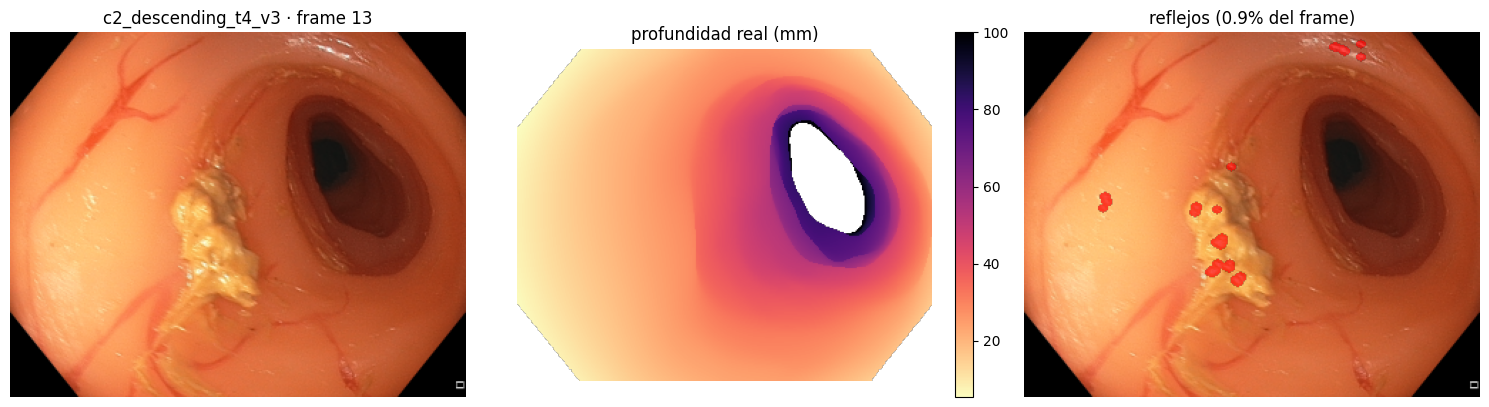

In [4]:
video = division["prueba"][0]
rgb, prof, mask = c3vd.cargar_video(video)
i = len(rgb) // 2
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(rgb[i]); ax[0].set_title(f"{video} · frame {i}")
im = ax[1].imshow(np.where(prof[i] > 0, prof[i], np.nan), cmap="magma_r"); ax[1].set_title("profundidad real (mm)")
plt.colorbar(im, ax=ax[1], fraction=0.04)
ax[2].imshow(rgb[i]); ax[2].imshow(np.ma.masked_where(~mask[i], mask[i]), cmap="autumn", alpha=0.7)
ax[2].set_title(f"reflejos ({100 * mask[i].mean():.1f}% del frame)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Endo-STTN congelado borra los reflejos

Endo-STTN no se entrena: **se usa el modelo preentrenado (`gen_00009.pth`) con la inferencia oficial**, que busca en
frames vecinos y de referencia el tejido que el reflejo oculta. Fuera de la máscara el frame no cambia.

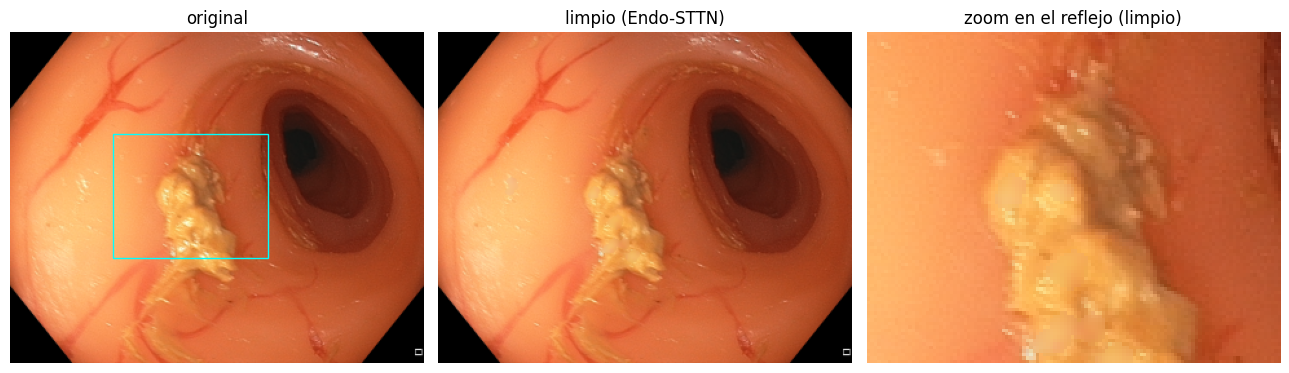

Píxeles cambiados fuera de la máscara: 0


In [5]:
if CORRER_LIMPIEZA:
    correr("codigo/limpiar_endosttn.py")

limpio = c3vd.cargar_video(video, "rgb_limpio")[0]
ys, xs = np.nonzero(mask[i]) if mask[i].any() else (np.array([128]), np.array([160]))
cy, cx = int(np.median(ys)), int(np.median(xs))
y0, x0 = np.clip(cy - 48, 0, rgb.shape[1] - 96), np.clip(cx - 60, 0, rgb.shape[2] - 120)
recorte = lambda a: a[y0:y0 + 96, x0:x0 + 120]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, img, t in zip(ax, [rgb[i], limpio[i], recorte(limpio[i])], ["original", "limpio (Endo-STTN)", "zoom en el reflejo (limpio)"]):
    a.imshow(img); a.set_title(t); a.axis("off")
ax[0].add_patch(plt.Rectangle((x0, y0), 120, 96, fill=False, color="cyan"))
plt.tight_layout(); plt.show()
print("Píxeles cambiados fuera de la máscara:", int((np.abs(limpio[i].astype(int) - rgb[i]).sum(-1)[~mask[i]] > 0).sum()))

## 3. Ajuste fino del estimador de profundidad

Se entrenan **dos** estimadores desde los mismos pesos (AF-SfMLearner, SCARED) y con la misma configuración:
**C** con frames originales y **D** con frames limpios. Pérdida *scale-invariant log* contra la profundidad real;
se guarda la época con menor AbsRel de validación.

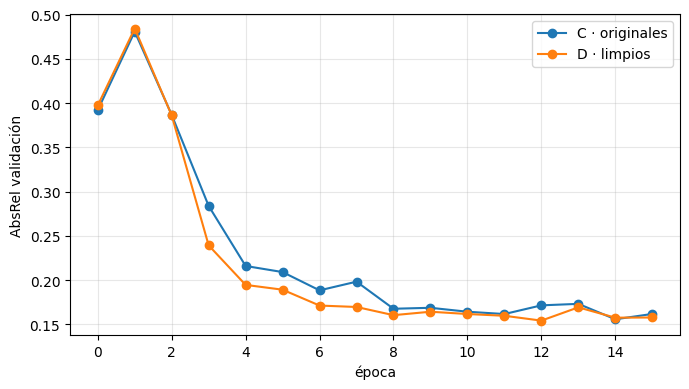

In [6]:
if CORRER_AJUSTE:
    for entrada in ["rgb", "rgb_limpio"]:
        correr("codigo/ajustar_profundidad.py", "--entrada", entrada, "--epocas", EPOCAS, "--semilla", SEMILLA)

fig, ax = plt.subplots(figsize=(7, 4))
for entrada, nombre in [("rgb", "C · originales"), ("rgb_limpio", "D · limpios")]:
    h = c3vd.DIR_MODELOS / f"{entrada}_s{SEMILLA}" / "historial.json"
    if h.exists():
        ep = json.load(open(h))["epocas"]
        ax.plot([e["epoca"] for e in ep], [e["abs_rel_val"] for e in ep], "o-", label=nombre)
ax.set_xlabel("época"); ax.set_ylabel("AbsRel validación"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. Evaluación en videos no vistos

| Modelo | Pesos | Frames de prueba |
|---|---|---|
| A | AF-SfMLearner (SCARED) | originales |
| B | AF-SfMLearner (SCARED) | limpios |
| C | ajustado con originales | originales |
| D | ajustado con limpios | limpios |

Métricas con *median scaling* (escala calculada con toda la imagen), en tres regiones: toda la imagen,
dentro de los reflejos y un anillo de 10 px alrededor. Wilcoxon pareado por frame.

In [7]:
if CORRER_EVALUAR:
    correr("codigo/evaluar_profundidad.py", "--semilla", SEMILLA)
from IPython.display import Markdown, display
display(Markdown(open(c3vd.DIR_RESULTADOS / "evaluacion_resumen.md").read()))

Videos de prueba: c2_descending_t4_v3  
Ajuste fino: semilla 0

### Región: imagen

| modelo   |   abs_rel |   sq_rel |    rmse |   rmse_log |     a1 |
|:---------|----------:|---------:|--------:|-----------:|-------:|
| A        |    0.4043 |   6.8161 | 18.4183 |     0.52   | 0.3827 |
| B        |    0.3986 |   6.7272 | 18.3621 |     0.5158 | 0.3863 |
| C        |    0.089  |   0.3337 |  3.6683 |     0.1122 | 0.9497 |
| D        |    0.078  |   0.3207 |  3.8201 |     0.1016 | 0.9575 |

### Región: reflejos

| modelo   |   abs_rel |   sq_rel |   rmse |   rmse_log |     a1 |
|:---------|----------:|---------:|-------:|-----------:|-------:|
| A        |    0.7526 |   7.2207 | 7.5409 |     0.5636 | 0.2536 |
| B        |    0.7442 |   7.1443 | 7.4511 |     0.558  | 0.2598 |
| C        |    0.1109 |   0.2416 | 1.9549 |     0.1304 | 0.9292 |
| D        |    0.0854 |   0.2021 | 1.71   |     0.1103 | 0.9101 |

### Región: anillo

| modelo   |   abs_rel |   sq_rel |   rmse |   rmse_log |     a1 |
|:---------|----------:|---------:|-------:|-----------:|-------:|
| A        |    0.4757 |   3.9758 | 6.3784 |     0.4389 | 0.417  |
| B        |    0.4572 |   3.6845 | 6.1984 |     0.427  | 0.4213 |
| C        |    0.1038 |   0.2432 | 2.0358 |     0.125  | 0.9251 |
| D        |    0.0749 |   0.1757 | 1.7151 |     0.1007 | 0.9311 |

### Wilcoxon pareado (H1: el segundo modelo tiene menor AbsRel)

| comparacion   | region   | metrica   |   n_frames |   mediana_dif |    p_valor |
|:--------------|:---------|:----------|-----------:|--------------:|-----------:|
| C vs D        | reflejos | abs_rel   |         26 |    0.0282615  | 0.0145755  |
| A vs B        | reflejos | abs_rel   |         26 |    0.00204836 | 0.134353   |
| C vs D        | imagen   | abs_rel   |         26 |    0.0179869  | 0.00046739 |


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/content/repo/codigo/modelo_profundidad.py:47: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:21

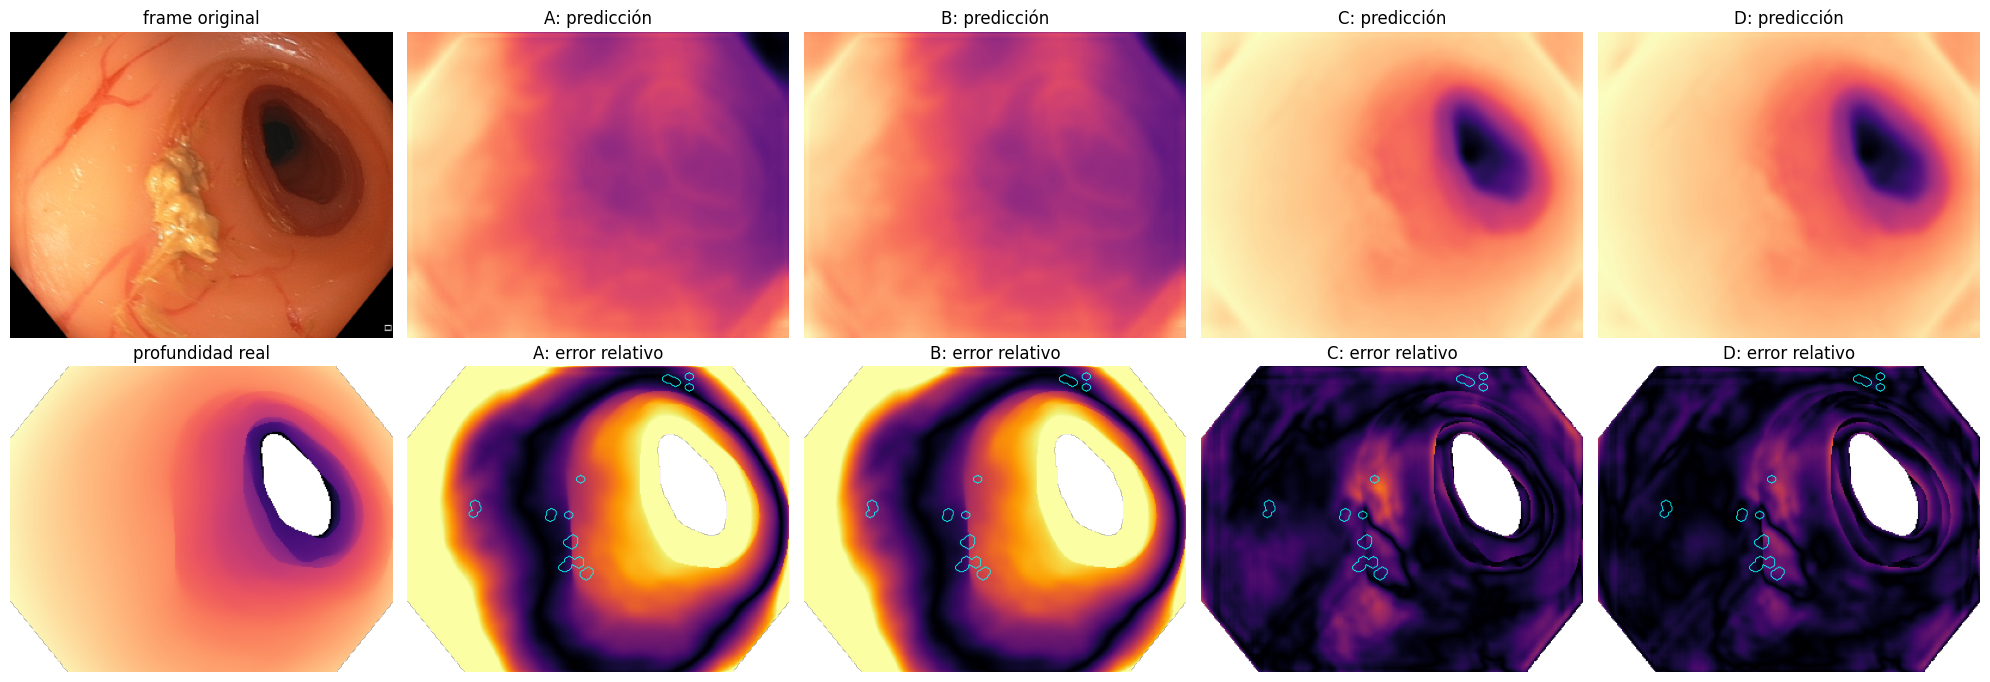

In [8]:
modelos = {"A": (mp.PESOS_SCARED, "rgb"), "B": (mp.PESOS_SCARED, "rgb_limpio"),
           "C": (c3vd.DIR_MODELOS / f"rgb_s{SEMILLA}", "rgb"), "D": (c3vd.DIR_MODELOS / f"rgb_limpio_s{SEMILLA}", "rgb_limpio")}
g = np.asarray(prof[i], np.float32); valido = g > 0
fig, ax = plt.subplots(2, 5, figsize=(20, 7))
ax[0, 0].imshow(rgb[i]); ax[0, 0].set_title("frame original")
ax[1, 0].imshow(np.where(valido, g, np.nan), cmap="magma_r"); ax[1, 0].set_title("profundidad real")
for j, (nombre, (pesos, entrada)) in enumerate(modelos.items(), 1):
    if not (Path(pesos) / "encoder.pth").exists():
        ax[0, j].set_title(f"{nombre}: sin modelo"); continue
    enc, dec = mp.cargar(pesos, DEVICE); enc.eval(); dec.eval()
    x = c3vd.cargar_video(video, entrada)[0][i:i + 1]
    with torch.no_grad():
        p = mp.predecir(enc, dec, mp.a_tensor(x, DEVICE))[0, 0].cpu().numpy()
    p = p * np.median(g[valido]) / np.median(p[valido])
    err = np.where(valido, np.abs(p - g) / np.maximum(g, 1e-3), np.nan)
    ax[0, j].imshow(p, cmap="magma_r"); ax[0, j].set_title(f"{nombre}: predicción")
    ax[1, j].imshow(err, cmap="inferno", vmin=0, vmax=0.5); ax[1, j].set_title(f"{nombre}: error relativo")
    ax[1, j].contour(mask[i], [0.5], colors="cyan", linewidths=0.6)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [9]:
# Guardar modelos y resultados en Drive
for carpeta in [c3vd.DIR_MODELOS, c3vd.DIR_RESULTADOS]:
    if carpeta.exists():
        shutil.copytree(carpeta, DRIVE / carpeta.name, dirs_exist_ok=True)
print("Copiado a", DRIVE)

Copiado a /content/drive/MyDrive/Equipo19


## 5. Cómo leer los resultados

- **D < C en AbsRel dentro de los reflejos** (Wilcoxon p < 0.05) y sin empeorar en toda la imagen: entrenar con frames
  limpios mejora la profundidad donde había reflejos. Es el resultado buscado.
- **B < A**: limpiar ayuda incluso sin reentrenar el estimador.
- **C ≈ D**: el estimador ya tolera los reflejos de C3VDv2, o la limpieza no aporta información útil.
- Si D mejora en la imagen pero no en los reflejos, la ganancia viene de otro lado (p. ej., estabilidad del entrenamiento).

Repite con otras semillas (`SEMILLA = 1, 2`) para comprobar que la diferencia no es casualidad.